In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tifffile
from skimage.measure import label, regionprops
from pathlib import Path

In [192]:
# =========================
# CELL 2 — USER INPUTS
# =========================

# File names
original_file = "/Users/parth/dev/boekhoven_lab/data/population_analysis/rna_peg_2.tif"
cy3_mask_file = "/Users/parth/dev/boekhoven_lab/data/population_analysis/rna_peg_2_cy3_10.tif"
cy5_mask_file = "/Users/parth/dev/boekhoven_lab/data/population_analysis/rna_peg_2_cy5_74.tif"

# Experimental information
condition = "PEG"
replicate = "2"

# Timing
start_time = 150      # seconds; 2 min 30 s
frame_interval = 6.867  # seconds/frame

# Output folder
output_folder = Path("rna_peg_2_analysis_10_104")
output_folder.mkdir(exist_ok=True)

print("Analysis setup:")
print(f"Condition:       {condition}")
print(f"Replicate:       {replicate}")
print(f"Start time:      {start_time:.3f} s")
print(f"Frame interval:  {frame_interval:.5f} s")

Analysis setup:
Condition:       PEG
Replicate:       2
Start time:      150.000 s
Frame interval:  6.86700 s


In [193]:
# =========================
# CELL 3 — LOAD TIFF FILES
# =========================

original = tifffile.imread(original_file)
cy3_mask = tifffile.imread(cy3_mask_file)
cy5_mask = tifffile.imread(cy5_mask_file)

print("Original:", original.shape, original.dtype)
print("Cy3 mask:", cy3_mask.shape, cy3_mask.dtype)
print("Cy5 mask:", cy5_mask.shape, cy5_mask.dtype)

Original: (84, 2, 1024, 1024) uint8
Cy3 mask: (84, 1024, 1024) uint8
Cy5 mask: (84, 1024, 1024) uint8


In [194]:
# =========================
# CELL 4 — CHECK DIMENSIONS
# =========================

# Check mask dimensions
assert cy3_mask.ndim == 3, "Cy3 mask should be a 3D stack: frames × Y × X"
assert cy5_mask.ndim == 3, "Cy5 mask should be a 3D stack: frames × Y × X"

# Check that masks have the same dimensions
assert cy3_mask.shape == cy5_mask.shape, (
    f"Cy3 and Cy5 masks have different shapes: "
    f"{cy3_mask.shape} vs {cy5_mask.shape}"
)

n_frames, height, width = cy3_mask.shape

# Check original image
assert original.shape[0] == n_frames, (
    f"Original has {original.shape[0]} frames, "
    f"but masks have {n_frames}"
)

print(f"Number of frames: {n_frames}")
print(f"Image dimensions: {height} × {width}")
print(f"Total duration: {(n_frames - 1) * frame_interval:.2f} s")
print(f"Final experimental time: {start_time + (n_frames - 1) * frame_interval:.2f} s")

Number of frames: 84
Image dimensions: 1024 × 1024
Total duration: 569.96 s
Final experimental time: 719.96 s


In [195]:
# =========================
# CELL 5 — CONVERT MASKS TO BOOLEAN
# =========================

cy3 = cy3_mask > 0
cy5 = cy5_mask > 0

print("Cy3 foreground pixels:", np.sum(cy3))
print("Cy5 foreground pixels:", np.sum(cy5))

Cy3 foreground pixels: 318285
Cy5 foreground pixels: 215583


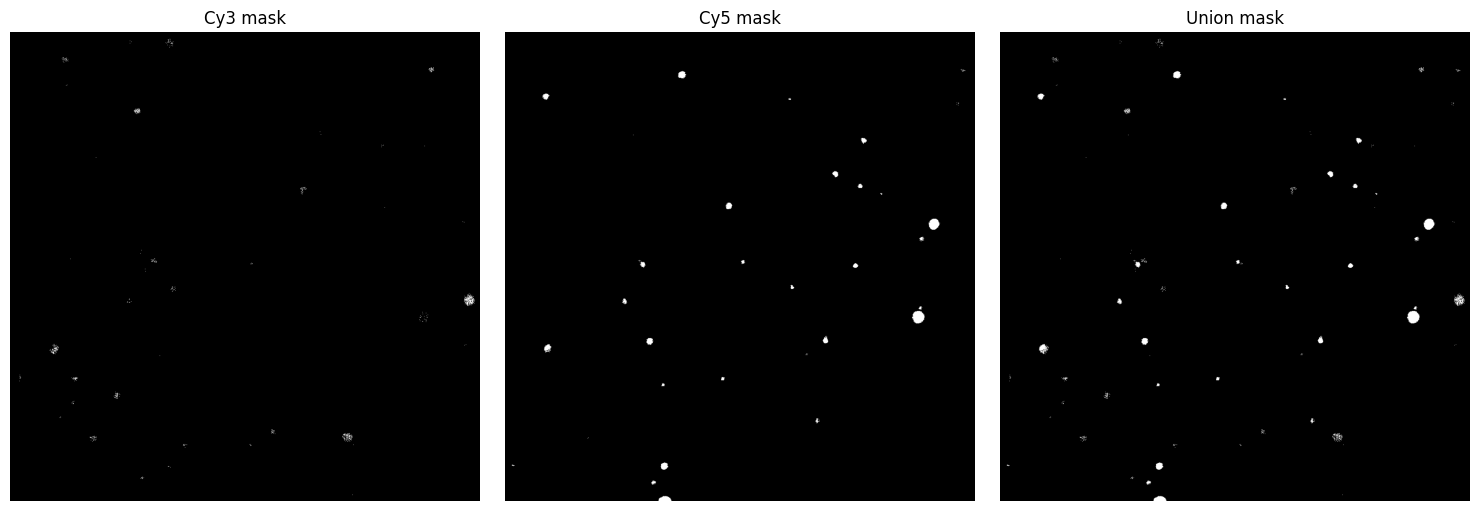

In [196]:
# =========================
# CELL 6 — VISUAL QC
# =========================

frame_to_view = 0

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cy3[frame_to_view], cmap="gray")
axes[0].set_title("Cy3 mask")

axes[1].imshow(cy5[frame_to_view], cmap="gray")
axes[1].set_title("Cy5 mask")

axes[2].imshow(cy3[frame_to_view] | cy5[frame_to_view], cmap="gray")
axes[2].set_title("Union mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

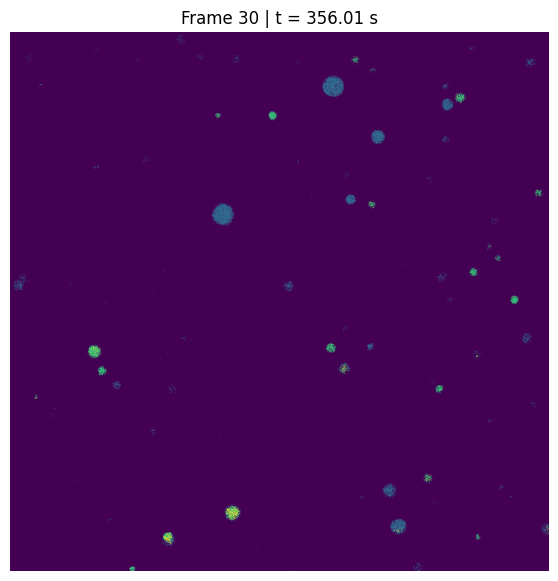

In [197]:
# =========================
# CELL 7 — OVERLAP VISUALISATION
# =========================

frame_to_view = 30

c3 = cy3[frame_to_view]
c5 = cy5[frame_to_view]

overlap = c3 & c5

fig, ax = plt.subplots(figsize=(7, 7))

# Show the three possible regions:
# Cy3 only, Cy5 only, and overlap
display_image = (
    c3.astype(int)
    + 2 * c5.astype(int)
)

ax.imshow(display_image)
ax.set_title(
    f"Frame {frame_to_view} | "
    f"t = {start_time + frame_to_view * frame_interval:.2f} s"
)
ax.axis("off")

plt.show()

In [198]:
# =========================
# CELL 8 — PIXEL-LEVEL OVERLAP
# =========================

results = []

for frame in range(n_frames):

    c3 = cy3[frame]
    c5 = cy5[frame]

    area_cy3 = np.sum(c3)
    area_cy5 = np.sum(c5)

    overlap_area = np.sum(c3 & c5)
    union_area = np.sum(c3 | c5)

    # Jaccard index
    if union_area > 0:
        jaccard = overlap_area / union_area
    else:
        jaccard = np.nan

    # Dice coefficient
    if (area_cy3 + area_cy5) > 0:
        dice = 2 * overlap_area / (area_cy3 + area_cy5)
    else:
        dice = np.nan

    # Fraction of Cy3 area overlapping Cy5
    if area_cy3 > 0:
        cy3_overlap_fraction = overlap_area / area_cy3
    else:
        cy3_overlap_fraction = np.nan

    # Fraction of Cy5 area overlapping Cy3
    if area_cy5 > 0:
        cy5_overlap_fraction = overlap_area / area_cy5
    else:
        cy5_overlap_fraction = np.nan

    results.append({
        "condition": condition,
        "replicate": replicate,
        "frame": frame,
        "time_s": start_time + frame * frame_interval,
        "time_min": (start_time + frame * frame_interval) / 60,

        "cy3_area_px": area_cy3,
        "cy5_area_px": area_cy5,
        "overlap_area_px": overlap_area,
        "union_area_px": union_area,

        "jaccard": jaccard,
        "dice": dice,

        "cy3_overlap_fraction": cy3_overlap_fraction,
        "cy5_overlap_fraction": cy5_overlap_fraction
    })

pixel_results = pd.DataFrame(results)

pixel_results.head()

,condition,replicate,frame,time_s,time_min,cy3_area_px,cy5_area_px,overlap_area_px,union_area_px,jaccard,dice,cy3_overlap_fraction,cy5_overlap_fraction
0,PEG,2,0,150.000,2.50000,982,3311,73,4220,0.017299,0.034009,0.074338,0.022048
1,PEG,2,1,156.867,2.61445,1146,1761,26,2881,0.009025,0.017888,0.022688,0.014764
2,PEG,2,2,163.734,2.72890,826,2136,40,2922,0.013689,0.027009,0.048426,0.018727
3,PEG,2,3,170.601,2.84335,574,2409,25,2958,0.008452,0.016762,0.043554,0.010378
4,PEG,2,4,177.468,2.95780,934,3066,19,3981,0.004773,0.009500,0.020343,0.006197


In [199]:
# =========================
# CELL 9 — RESULTS TABLE
# =========================

pixel_results

,condition,replicate,frame,time_s,time_min,cy3_area_px,cy5_area_px,overlap_area_px,union_area_px,jaccard,dice,cy3_overlap_fraction,cy5_overlap_fraction
0,PEG,2,0,150.000,2.50000,982,3311,73,4220,0.017299,0.034009,0.074338,0.022048
1,PEG,2,1,156.867,2.61445,1146,1761,26,2881,0.009025,0.017888,0.022688,0.014764
2,PEG,2,2,163.734,2.72890,826,2136,40,2922,0.013689,0.027009,0.048426,0.018727
3,PEG,2,3,170.601,2.84335,574,2409,25,2958,0.008452,0.016762,0.043554,0.010378
4,PEG,2,4,177.468,2.95780,934,3066,19,3981,0.004773,0.009500,0.020343,0.006197
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,PEG,2,79,692.493,11.54155,948,773,123,1598,0.076971,0.142940,0.129747,0.159120
80,PEG,2,80,699.360,11.65600,1024,789,145,1668,0.086930,0.159956,0.141602,0.183777
81,PEG,2,81,706.227,11.77045,951,837,151,1637,0.092242,0.168904,0.158780,0.180406
82,PEG,2,82,713.094,11.88490,765,519,90,1194,0.075377,0.140187,0.117647,0.173410


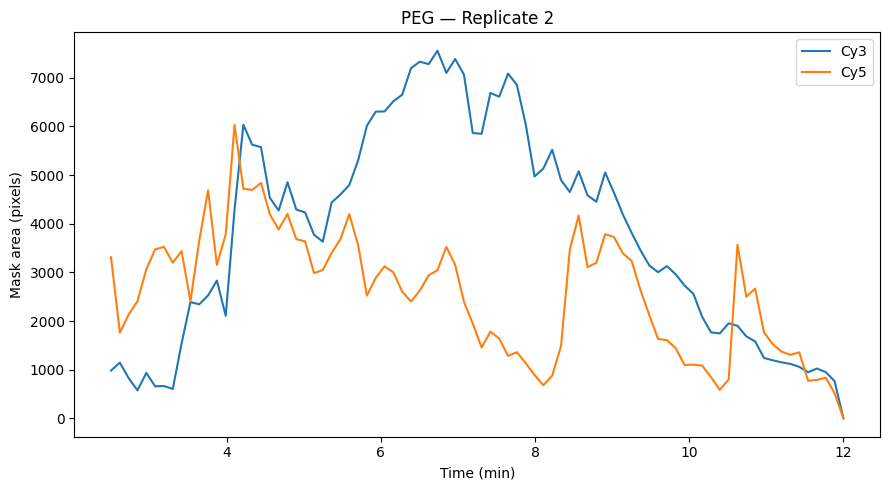

In [200]:
# =========================
# CELL 10 — CY3/CY5 AREA
# =========================

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=pixel_results,
    x="time_min",
    y="cy3_area_px",
    label="Cy3"
)

sns.lineplot(
    data=pixel_results,
    x="time_min",
    y="cy5_area_px",
    label="Cy5"
)

plt.xlabel("Time (min)")
plt.ylabel("Mask area (pixels)")
plt.title(f"{condition} — Replicate {replicate}")
plt.tight_layout()
plt.show()

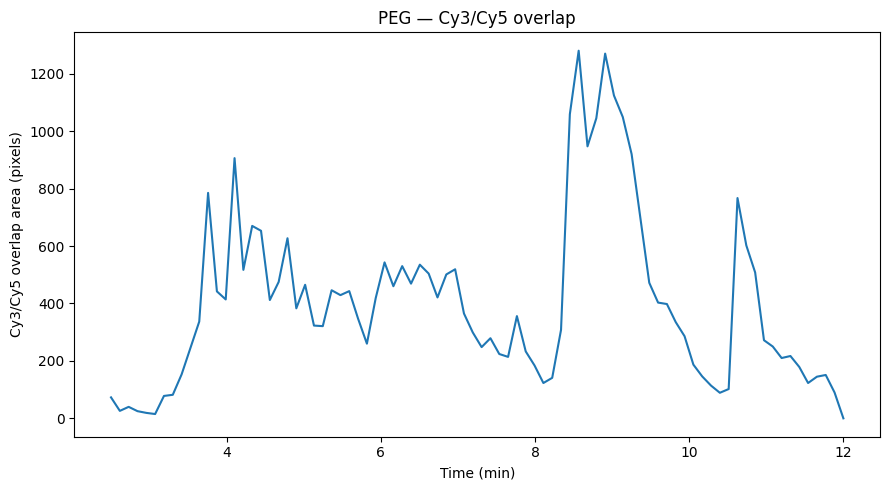

In [201]:
# =========================
# CELL 11 — OVERLAP AREA
# =========================

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=pixel_results,
    x="time_min",
    y="overlap_area_px"
)

plt.xlabel("Time (min)")
plt.ylabel("Cy3/Cy5 overlap area (pixels)")
plt.title(f"{condition} — Cy3/Cy5 overlap")
plt.tight_layout()
plt.show()

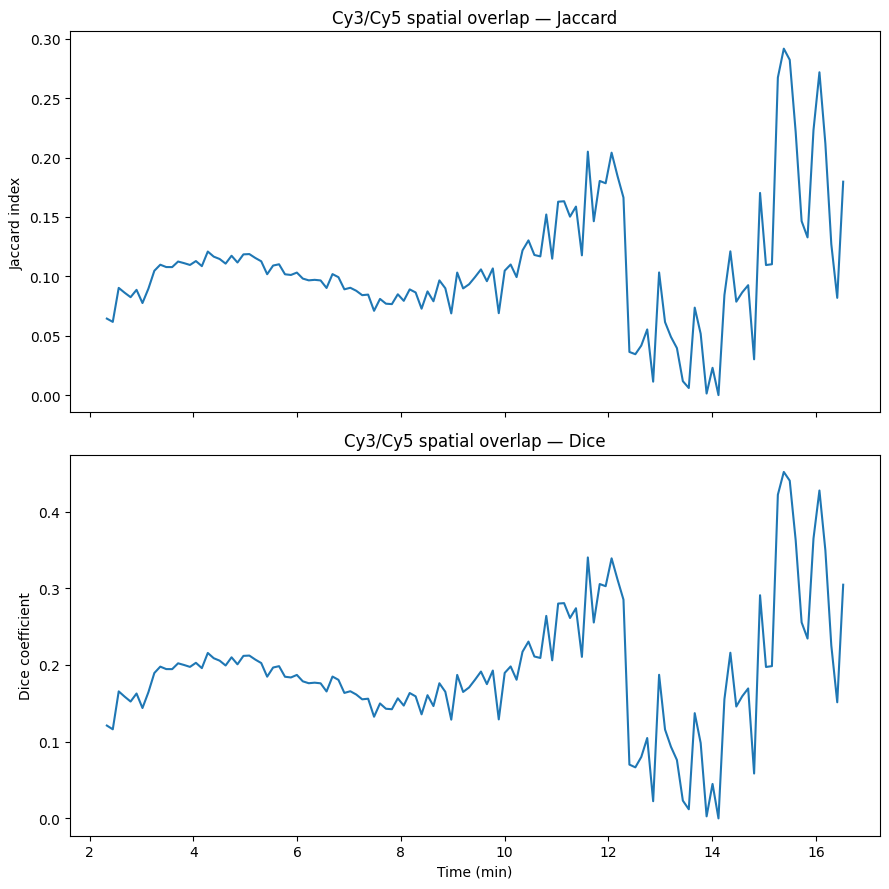

In [165]:
# =========================
# CELL 12 — JACCARD AND DICE
# =========================

fig, axes = plt.subplots(2, 1, figsize=(9, 9), sharex=True)

sns.lineplot(
    data=pixel_results,
    x="time_min",
    y="jaccard",
    ax=axes[0]
)

axes[0].set_ylabel("Jaccard index")
axes[0].set_title("Cy3/Cy5 spatial overlap — Jaccard")

sns.lineplot(
    data=pixel_results,
    x="time_min",
    y="dice",
    ax=axes[1]
)

axes[1].set_xlabel("Time (min)")
axes[1].set_ylabel("Dice coefficient")
axes[1].set_title("Cy3/Cy5 spatial overlap — Dice")

plt.tight_layout()
plt.show()

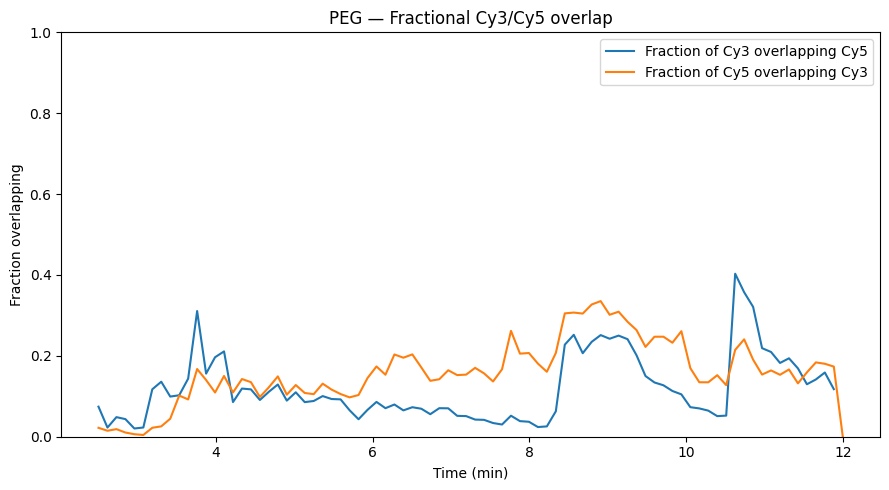

In [202]:
# =========================
# CELL 13 — ASYMMETRIC OVERLAP
# =========================

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=pixel_results,
    x="time_min",
    y="cy3_overlap_fraction",
    label="Fraction of Cy3 overlapping Cy5"
)

sns.lineplot(
    data=pixel_results,
    x="time_min",
    y="cy5_overlap_fraction",
    label="Fraction of Cy5 overlapping Cy3"
)

plt.xlabel("Time (min)")
plt.ylabel("Fraction overlapping")
plt.ylim(0, 1)
plt.title(f"{condition} — Fractional Cy3/Cy5 overlap")
plt.tight_layout()
plt.show()

In [203]:
# ============================================================
# CELL 14 — Fast object-level analysis with minimum-size filter
# ============================================================

# Minimum object area in pixels²
# Adjust this value after visually inspecting your segmentation.
min_object_area = 20

object_summary = []

for frame in range(n_frames):

    c3 = cy3[frame]
    c5 = cy5[frame]

    # --------------------------------------------------------
    # 1. Combine Cy3 and Cy5 masks
    # --------------------------------------------------------
    union = c3 | c5

    # --------------------------------------------------------
    # 2. Label connected objects
    # --------------------------------------------------------
    labelled = label(union, connectivity=2)

    # --------------------------------------------------------
    # 3. Remove objects smaller than min_object_area
    # --------------------------------------------------------
    object_sizes = np.bincount(labelled.ravel())

    # Label 0 is the background, so exclude it
    valid_labels = np.where(object_sizes >= min_object_area)[0]
    valid_labels = valid_labels[valid_labels != 0]

    # Create filtered mask
    filtered_union = np.isin(labelled, valid_labels)

    # Re-label after removing small objects
    labelled = label(filtered_union, connectivity=2)

    # Number of remaining objects
    n_objects = labelled.max()

    time_s = start_time + frame * frame_interval

    # --------------------------------------------------------
    # 4. Handle frames with no objects
    # --------------------------------------------------------
    if n_objects == 0:

        object_summary.append({
            "condition": condition,
            "replicate": replicate,
            "frame": frame,
            "time_s": time_s,
            "time_min": time_s / 60,
            "total_objects": 0,
            "cy3_only": 0,
            "cy5_only": 0,
            "dual_labelled": 0,
            "fraction_dual": np.nan
        })

        continue

    # --------------------------------------------------------
    # 5. Identify which objects contain Cy3 and Cy5
    # --------------------------------------------------------

    cy3_objects = np.unique(labelled[c3])
    cy3_objects = cy3_objects[cy3_objects > 0]

    cy5_objects = np.unique(labelled[c5])
    cy5_objects = cy5_objects[cy5_objects > 0]

    cy3_objects = set(cy3_objects)
    cy5_objects = set(cy5_objects)

    # Objects containing both channels
    dual = cy3_objects & cy5_objects

    # Objects containing only one channel
    cy3_only = cy3_objects - cy5_objects
    cy5_only = cy5_objects - cy3_objects

    total = len(cy3_objects | cy5_objects)

    # --------------------------------------------------------
    # 6. Store frame-level summary
    # --------------------------------------------------------

    object_summary.append({
        "condition": condition,
        "replicate": replicate,
        "frame": frame,
        "time_s": time_s,
        "time_min": time_s / 60,
        "total_objects": total,
        "cy3_only": len(cy3_only),
        "cy5_only": len(cy5_only),
        "dual_labelled": len(dual),
        "fraction_dual": (
            len(dual) / total if total > 0 else np.nan
        )
    })


# Convert to DataFrame
object_summary = pd.DataFrame(object_summary)

print("Object analysis complete!")
print(f"Minimum object area: {min_object_area} pixels²")
print(f"Frames analysed: {len(object_summary)}")

display(object_summary.head())

Object analysis complete!
Minimum object area: 20 pixels²
Frames analysed: 84


,condition,replicate,frame,time_s,time_min,total_objects,cy3_only,cy5_only,dual_labelled,fraction_dual
0,PEG,2,0,150.000,2.50000,30,6,20,4,0.133333
1,PEG,2,1,156.867,2.61445,25,7,14,4,0.160000
2,PEG,2,2,163.734,2.72890,26,8,13,5,0.192308
3,PEG,2,3,170.601,2.84335,20,4,11,5,0.250000
4,PEG,2,4,177.468,2.95780,27,7,17,3,0.111111


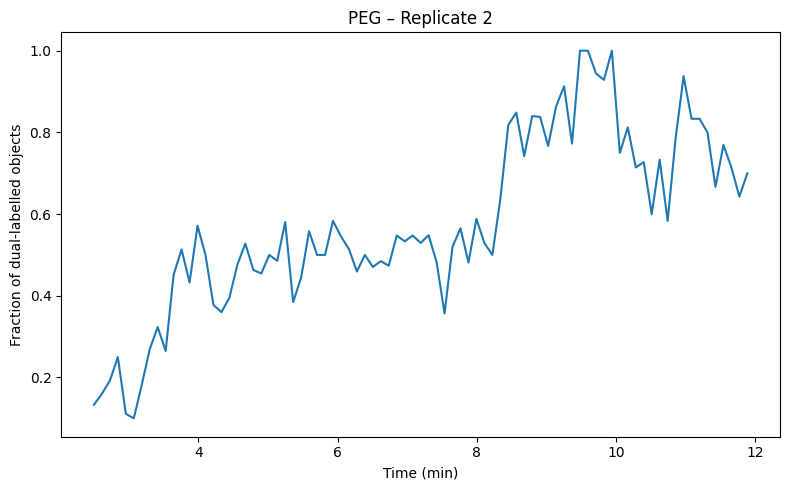

In [204]:
# =========================
# CELL 15 — OBJECT COUNTS
# =========================

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=object_summary,
    x="time_min",
    y="fraction_dual"
)

plt.xlabel("Time (min)")
plt.ylabel("Fraction of dual-labelled objects")
plt.title(f"{condition} – Replicate {replicate}")
plt.tight_layout()
plt.show()

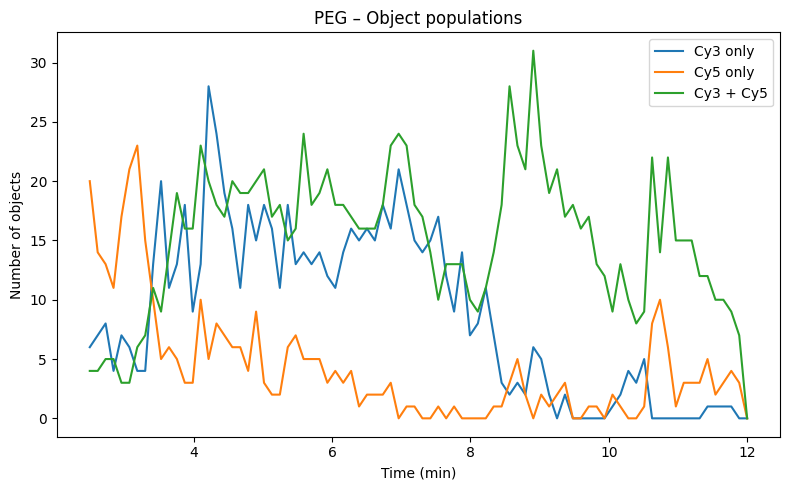

In [205]:
# =========================
# CELL 16 — OBJECT COUNT TABLE
# =========================

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=object_summary,
    x="time_min",
    y="cy3_only",
    label="Cy3 only"
)

sns.lineplot(
    data=object_summary,
    x="time_min",
    y="cy5_only",
    label="Cy5 only"
)

sns.lineplot(
    data=object_summary,
    x="time_min",
    y="dual_labelled",
    label="Cy3 + Cy5"
)

plt.xlabel("Time (min)")
plt.ylabel("Number of objects")
plt.title(f"{condition} – Object populations")
plt.tight_layout()
plt.show()

In [207]:
object_csv = output_folder / "rna_peg_2_10_74_object_summary.csv"

object_summary.to_csv(object_csv, index=False)

print(f"Saved: {object_csv}")

Saved: rna_peg_2_analysis_10_104/rna_peg_2_10_74_object_summary.csv


In [206]:
# =========================
# CELL 20 — SAVE PIXEL RESULTS
# =========================

pixel_output = output_folder / "rna_peg_2_10_74_pixel_overlap.csv"

pixel_results.to_csv(pixel_output, index=False)

print(f"Saved: {pixel_output}")

Saved: rna_peg_2_analysis_10_104/rna_peg_2_10_74_pixel_overlap.csv
